# E91: How big is each Qwen update at the template fine-tune's size, and what has it learned there?

**The answer.** The table exists, and it carries a warning. Every arm has a named state nearest the template fine-tune's full update. At that size the TOFU update has not learned its facts: it reads like the unchanged model. It passes the filed learning line only past step 500, at least thirty times that norm. So a matched-step reading compares a finished template update with the first steps of a facts update. The user has been asked whether the comparison should stop leaning on it.


## What we were trying to test

The Qwen comparison needs its updates read at a common size, because the TOFU update ends 37 times larger than the template one. The amended plan makes the size-matched step the reading the comparison leans on. This job finds that step for each arm, and asks whether the TOFU update has learned anything by then.

**The reference** is anchor 1's full update at step 100. Anchor 1 is the template fine-tune, which teaches an answer format the model already follows under a prompt. It reads the two sizes below at 0.4865 and 0.0959.

**Two sizes, read on each saved state.** The unchanged model reads 0 on both.

- **Norm:** the Frobenius norm of the update over the decomposed matrices.
- **KL to start:** $\mathrm{KL}(W_0 \,\|\, W_0 + \delta W)$ per position on the first 16 maths rows, the rows anchor 1's training tracked.

"Nearest" is the smallest absolute log ratio to the reference. An arm that never reaches the reference gets its largest state, flagged.

**The arms.**

- **Anchor 1, two seeds.** The second seed shows how far a repeat lands from the reference.
- **Anchor 2, two seeds.** The fine-tune on TOFU facts about invented authors, the example of content the model lacks.
- **RL and its shuffled-reward null, two seeds each.** The null shows what the same loop moves without a meaningful reward.
- **Own-samples SFT, one seed.** The same prompts and rate as RL, with the model's own correct samples as targets.
- **u1 and u2.** Fine-tunes on GSM8K's human solutions, u1 with no warm-up and u2 with a short one.

**The second stage.** Anchor 2 had no saved state near the reference, so both seeds were retrained and saved at steps 27 to 30. We then read its fact answers there.

**New-word recall** is the share of the reference answer's words, absent from the question, that return in the model's answer. 0 means none and 1 means all. **The filed learning line** is 0.585, halfway from the unchanged model to the full update.


In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_size_grid")
RES = ROOT / "results"
load = lambda path: json.loads(path.read_text())
grid, matched = load(RES / "size_grid.json"), load(RES / "matched.json")
filed = load(RES / "predictions_matched.json")
read = load(ROOT.parent / "qwen_tofu_forms" / "results" / "read.json")


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in row) + " |" for row in rows]
    display(Markdown("\n".join(out)))


assert matched["done"] and all(s["label"] == "not learned" for s in matched["states"])
assert not any(grid["arms"][a]["at_norm"]["reached"] for a in ("R_s0", "R_s70", "N_s0", "N_s70", "F_s0"))
assert read["states"]["500"]["trained"]["recall"] < filed["learned_line"] < read["states"]["1000"]["trained"]["recall"]


## What we expected

- **The GSM8K arms:** nearest in norm at step 100, not reaching it.
- **KL, as leans with no record behind them:** RL, the null and own-samples SFT stay under the reference through step 100. u1 and u2 reach it before step 10. Anchor 2 crosses it between steps 50 and 500.
- **Anchor 2's retrain:** nearest near step 30 in norm, and between steps 25 and 45 in KL.
- **Learning:** not learned at any matched state, with trained-wording recall under 0.30. These steps sit inside a 250-step warm-up.

## What we observed

### Does the table exist, and which arms reach the reference?


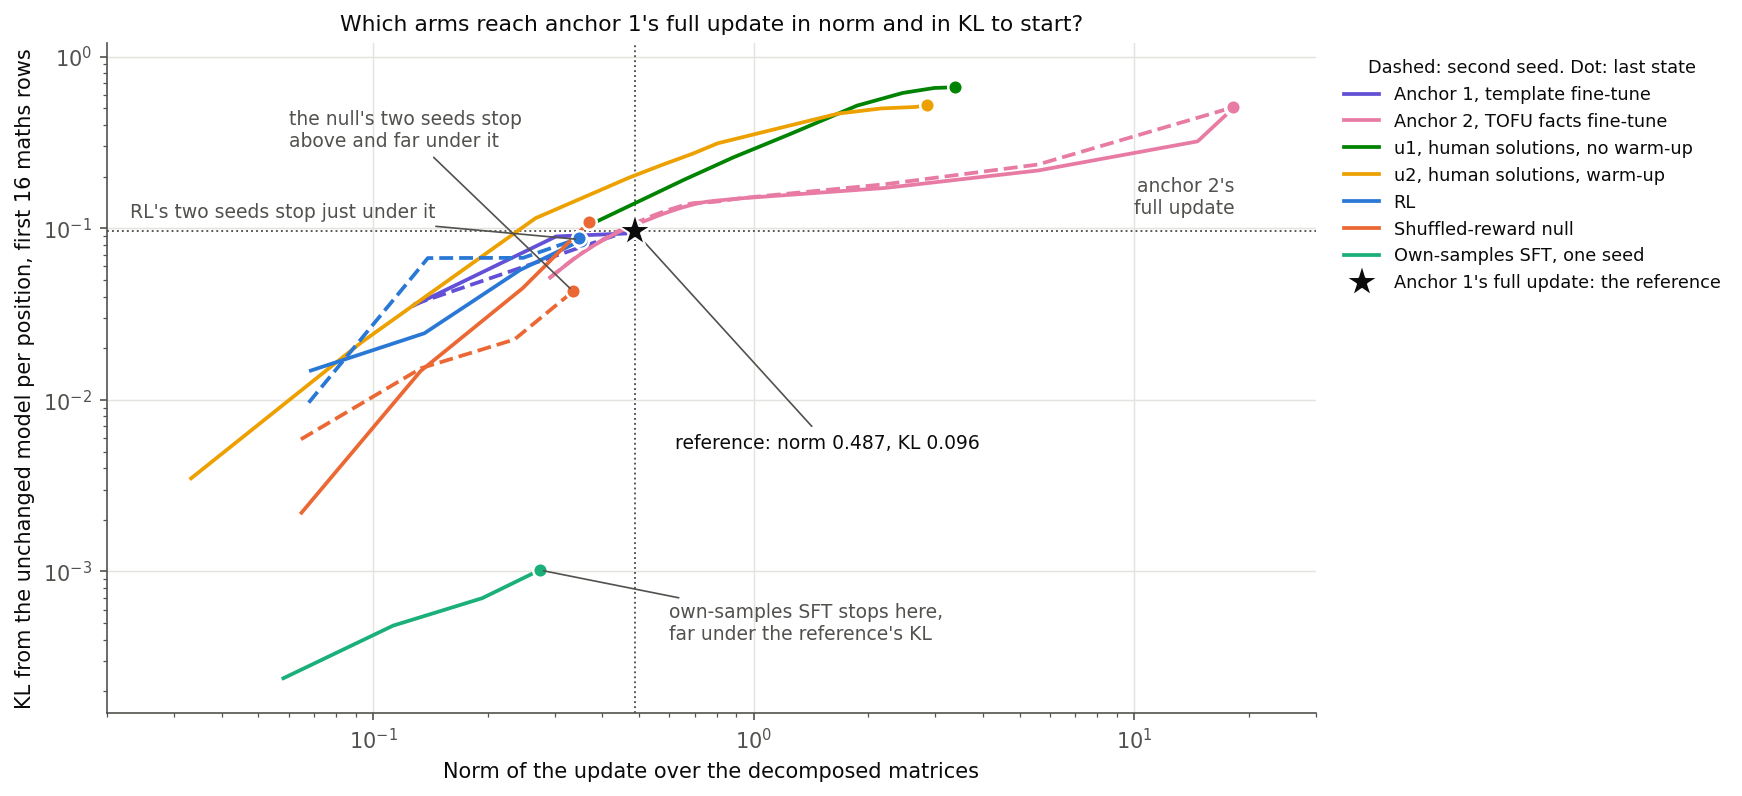

| arm | nearest norm: step | ratio to reference | nearest KL: step | ratio to reference |
|---|---|---|---|---|
| anchor 1, first seed | 100 | 1.00 | 100 | 1 |
| anchor 1, second seed | 100 | 1.00 | 100 | 1.04 |
| anchor 2, seed 42 | 29 | 0.98 | 27 | 0.983 |
| anchor 2, seed 142 | 30 | 1.02 | 27 | 0.991 |
| RL, first seed | 100 | 0.72, not reached | 100 | 0.883, not reached |
| null, first seed | 100 | 0.76, not reached | 100 | 1.13 |
| own-samples SFT | 100 | 0.56, not reached | 100 | 0.0106, not reached |
| RL, second seed | 100 | 0.71, not reached | 100 | 0.909, not reached |
| null, second seed | 100 | 0.69, not reached | 100 | 0.447, not reached |
| u1 | 1 | 0.77 | 1 | 1.1 |
| u2 | 7 | 0.97 | 5 | 1.19 |

In [2]:
display(Image(ROOT / "figures" / "norm_vs_kl.png", width=900))
names = {"anchor1_s0": "anchor 1, first seed", "anchor1_s1": "anchor 1, second seed", "anchor2_s0": "anchor 2, seed 42", "anchor2_s142": "anchor 2, seed 142",
         "R_s0": "RL, first seed", "R_s70": "RL, second seed", "N_s0": "null, first seed", "N_s70": "null, second seed", "F_s0": "own-samples SFT", "u1": "u1", "u2": "u2"}
table(["arm", "nearest norm: step", "ratio to reference", "nearest KL: step", "ratio to reference"],
      [[names[a], r["at_norm"]["step"], f"{r['at_norm']['ratio']:.2f}" + ("" if r["at_norm"]["reached"] else ", not reached"),
        r["at_kl"]["step"], f"{r['at_kl']['ratio']:.3g}" + ("" if r["at_kl"]["reached"] else ", not reached")] for a, r in grid["arms"].items()])


**Reading it.** Yes: every arm has a named state, but only some reach the reference. Anchor 2 passes almost through the star, and u1 and u2 pass above it. All five runs of RL, the null and own-samples SFT stop to its left, because none reaches the norm by step 100. In KL they differ widely. RL ends just under the reference at both seeds. The null's two seeds read 1.13 and 0.45 of it, 2.5 times apart, and one of them reaches it.

Own-samples SFT stops at 0.011 of the reference, at 0.56 of the norm. At step 100, RL's KL is about 80 times SFT's, with SFT's norm about 0.8 of RL's. We do not name a cause. The earlier report on this RL loop, E69, read KL on sampled answers and shows the same order at both seeds.


### Has anchor 2 learned its facts at that size?


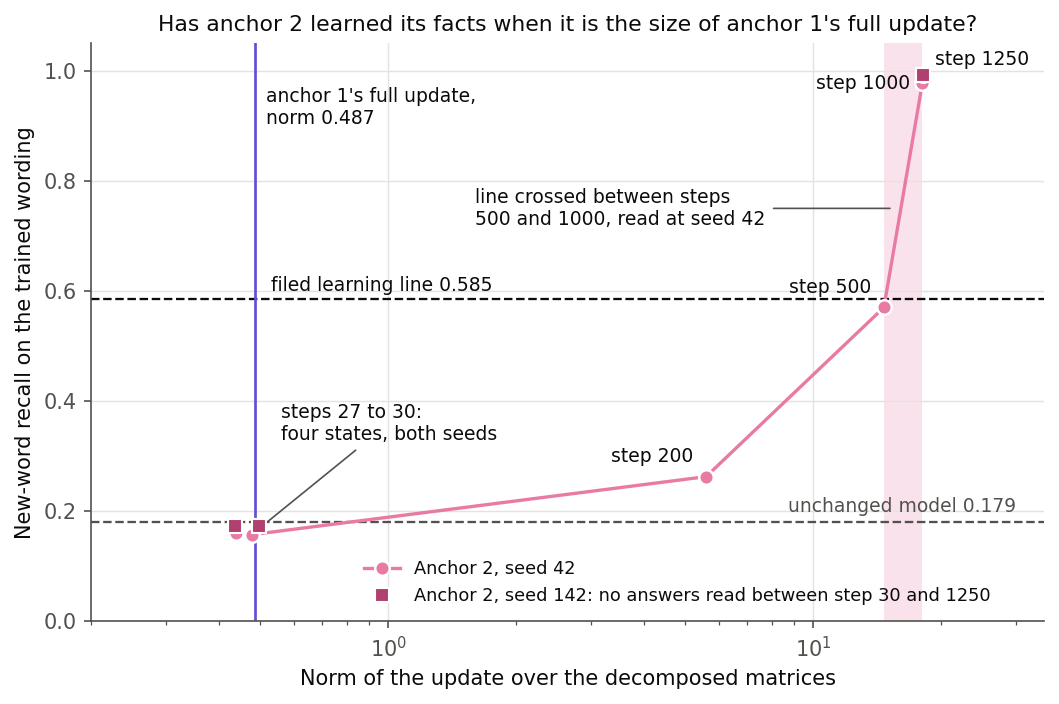

| seed, state | norm | trained-wording recall | filed rule |
|---|---|---|---|
| 42, step 27 | 0.438 | 0.159 | not learned |
| 42, step 29 | 0.477 | 0.157 | not learned |
| 142, step 27 | 0.436 | 0.172 | not learned |
| 142, step 30 | 0.496 | 0.173 | not learned |
| unchanged model | 0 | 0.179 | cannot pass |
| 42, step 200 | 5.597 | 0.262 | not learned |
| 42, step 500 | 14.667 | 0.570 | not learned |
| 42, step 1000 | 18.068 | 0.978 | learned |
| 42, step 1250 | 18.109 | 0.993 | learned |

In [3]:
display(Image(ROOT / "figures" / "recall_vs_norm.png", width=800))
rows = [[f"{s['seed']}, step {s['step']}", f"{s['norm']:.3f}", f"{s['answers']['trained']['recall']:.3f}", s["label"]] for s in matched["states"]]
rows.append(["unchanged model", 0, f"{read['W0']['trained']['recall']:.3f}", "cannot pass"])
rows += [[f"42, step {t}", f"{read['files'][t]['norm']:.3f}", f"{read['states'][t]['trained']['recall']:.3f}",
          "learned" if read["states"][t]["trained"]["recall"] >= filed["learned_line"] else "not learned"] for t in ("200", "500", "1000", "1250")]
table(["seed, state", "norm", "trained-wording recall", "filed rule"], rows)


**Reading it.** No. The filed rule reads "not learned" at all four matched states, both seeds, as expected. Trained-wording recall reads 0.157 to 0.173 against 0.179 unchanged, a little under it, and we do not name a cause. The full update reads 0.99 at both seeds. This wording is the easiest test, so the statement is the strong one.

Along the first TOFU run, recall reads 0.26 at step 200 and 0.57 at step 500, just under the line of 0.585, then 0.98 at step 1000. So the crossing lies between steps 500 and 1000, at a norm between 14.7 and 18.1. The size at which it has learned is at least 30 times the reference's. That run is seed 42 only, because seed 142 has no saved state there.

Anchor 1 clears its own filed learning rule at the reference size, by format rate. That rule counts format, not new words, so the two lines are not one scale.


## What we learned

Size matching and learning do not line up across the two examples. The state matching anchor 1's size exists and lies on the full update's path, but it reads like the unchanged model on the facts it is meant to teach. Any reading through the decomposition there says what the opening steps of a facts fine-tune do, not what new content looks like. The plan named this step as the one the comparison leans on. The user has been asked whether it should stop doing so, and that decision is open.

## How compelling is the evidence

- **Norm** says nothing of where the update lands.
- **KL** here is on maths rows only. It is off-task for the TOFU arm and says nothing of what it learned on facts.
- **Recall** counts new words only, so a state that has shifted toward fact-like answers without the facts reads near the unchanged model. Batch loss has already fallen from 6.24 to 2.39 by step 30 at seed 42, with recall flat.
- **Controls.** The zero state read 0 and 0. Anchor 1's step 100 read the earlier run's numbers.
- **Same path.** The retrain against the saved file at step 100 reads 0 at seed 142, on one card type. It reads 0.74% of the norm at seed 42, across two card types. The two seeds sit 90% apart, so the matched states are on the full update's path.
- **Seeds.** Two for each anchor, RL and the null, one for own-samples SFT. Recall along training has one seed.
- **Precision.** u1 and u2 exist only as bf16 files, the other arms as fp32.

## Surprises

Two filed leans missed, both leans and not gates. The null at its first seed reached the KL reference, where we leaned it would stay under through step 100. Anchor 2 crossed the KL reference between steps 20 and 50, where we leaned between 50 and 500.

One error in the first read: the state list left out u1's step 1 and u2's steps 1, 7, 8 and 9. The lead found this reading the first output, and they were read before the grid was committed. It changed both arms' norm-nearest step.

## What next

1. **The user's decision: should the comparison stop leaning on the matched step?** The answer decides what the anchor rows are read at.
2. **Reads through the decomposition at these states** are `qwen-decomp-lead`'s. A separation between the anchors at the matched step cannot come from facts the update recalls.
3. **A state just past the learning line, at both seeds,** would be needed if the decision calls for one.

## Departures from the literature

None: no outside source is cited for a definition, recipe or threshold.

## Scorecard

| Filed item | Claim | Read | Verdict |
|---|---|---|---|
| controls | zero state 0, 0; anchor 1 step 100 reads the earlier numbers | as filed | passes |
| `gsm8k_arms_norm` | step 100, not reached | 0.274 to 0.370, none reached | held |
| `kl_leans`, GSM8K | under the reference through step 100 | null, first seed, 1.13 | **lean missed** |
| `kl_leans`, u1 and u2 | reach it before step 10 | step 1, by step 5 | held |
| `kl_leans`, anchor 2 | crosses between steps 50 and 500 | between 20 and 50 | **lean missed** |
| `t_norm`, `t_kl` | about step 30; between 25 and 45 | 29, 30; 27, 27 | held |
| `learned` | not learned, recall under 0.30 | not learned, 0.157 to 0.173 | held |
| rerun control | under a tenth of the seeds' distance | 0.0074 and 0, against 0.899 | on the path |

## Not run

Think-mode answer sets; reads through the decomposition, which are `qwen-decomp-lead`'s; bare and real-fact answers at the matched states; u1's and u2's answers at their matched steps; a second seed of own-samples SFT; a state just past the learning line.

## Provenance

Cluster L40s, `debug` QoS, $0, jobs 52219 and 52238. Results in `experiments/qwen_size_grid/results/`, figures from its `plot.py`. Full tables and scoring: `reports/analyses/2026-11-05_analysis_e91-size-grid.md`.
